# 🎵 Introduction to Audio and Speech Processing
## ITAI 2373 Module 03: Audio and Preprocessing

Welcome to our hands-on journey into the fascinating world of audio processing! 🎧

### What You'll Learn Today (2 Hours)
By the end of this session, you'll be able to:
- 🌊 **Understand sound fundamentals** and how speech is digitally represented
- 📊 **Create and interpret spectrograms** for time-frequency analysis
- 🔍 **Extract meaningful features** from audio using MFCCs
- 🧹 **Apply preprocessing techniques** like filtering and noise reduction
- 🐍 **Implement everything in Python** using the powerful librosa library

### Why This Matters for NLP
Audio processing is the bridge between spoken language and text-based NLP. Every voice assistant, transcription service, and speech-to-text system relies on these fundamental techniques!

---
**💡 Pro Tip**: This notebook is designed to run perfectly on Google Colab for free! All audio samples are built into the libraries we'll use.

## 🛠️ Setup: Installing Our Audio Processing Toolkit

First, let's install and import all the libraries we'll need. Don't worry about understanding every import right now - we'll explain each tool as we use it!

**What we're installing:**
- `librosa`: The Swiss Army knife of audio processing 🎵
- `soundfile`: For reading/writing audio files 📁
- `noisereduce`: For cleaning up noisy audio 🧹
- `IPython`: For playing audio directly in the notebook 🔊

In [1]:
# Install required packages (this might take a minute on first run)
!pip install librosa soundfile noisereduce ipython matplotlib numpy

# Import all our audio processing tools
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import noisereduce as nr
from IPython.display import Audio, display
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style for better-looking graphs
plt.style.use('default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("🎉 All libraries installed successfully!")
print(f"📚 Librosa version: {librosa.__version__}")
print("🚀 Ready to process some audio!")

   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.3/1.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.3/1.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.3/1.0 MB ? eta -:--:--
   -------------------- ------------------- 0.5/1.0 MB 421.3 kB/s eta 0:00:02
   -------------------- ------------------- 0.5/1.0 MB 421.3 kB/s eta 0:00:02
   ------------------------------ --------- 0.8/1.0 MB 457.5 kB/s eta 0:00:01
   ------------------------------ --------- 0.8/1.0 MB 457.5 kB/s eta 0:00:01
   ---------------------------------------- 1.0/1.0 MB 499.5 kB/s  

# 🌊 Part 1: Understanding Sound and Digital Audio

## What is Sound?
Sound is simply **vibrations traveling through air** (or other materials). When we speak:
1. Our vocal cords vibrate 🗣️
2. This creates pressure waves in the air 🌊
3. Our ears detect these waves and our brain interprets them as speech 🧠

## Key Properties of Sound Waves:
- **Frequency**: How fast the wave vibrates (measured in Hz) - determines pitch
- **Amplitude**: How strong the wave is - determines loudness
- **Duration**: How long the sound lasts - determines timing

Let's load some real audio and explore these concepts!

In [2]:
# Load a built-in audio sample from librosa
# This is a short clip of someone saying "yes" - perfect for learning!
audio_file = librosa.ex('choice')  # Built-in example audio
y, sr = librosa.load(audio_file, sr=None)  # y = audio data, sr = sample rate

print(f"🎵 Loaded audio sample:")
print(f"   📊 Sample rate: {sr} Hz (samples per second)")
print(f"   ⏱️  Duration: {len(y)/sr:.2f} seconds")
print(f"   📈 Number of samples: {len(y):,}")
print(f"   🔊 Audio range: {y.min():.3f} to {y.max():.3f}")

# Let's listen to our audio sample!
print("\n🔊 Click play to hear the audio:")
display(Audio(y, rate=sr))

🎵 Loaded audio sample:
   📊 Sample rate: 22050 Hz (samples per second)
   ⏱️  Duration: 25.03 seconds
   📈 Number of samples: 551,823
   🔊 Audio range: -0.329 to 0.381

🔊 Click play to hear the audio:


## 📈 Visualizing Sound: The Waveform

A **waveform** shows how the audio signal changes over time. Think of it as a graph where:
- **X-axis**: Time (when things happen)
- **Y-axis**: Amplitude (how loud things are)
- **Positive/Negative values**: The direction of air pressure changes

Let's plot our audio to see what speech looks like!

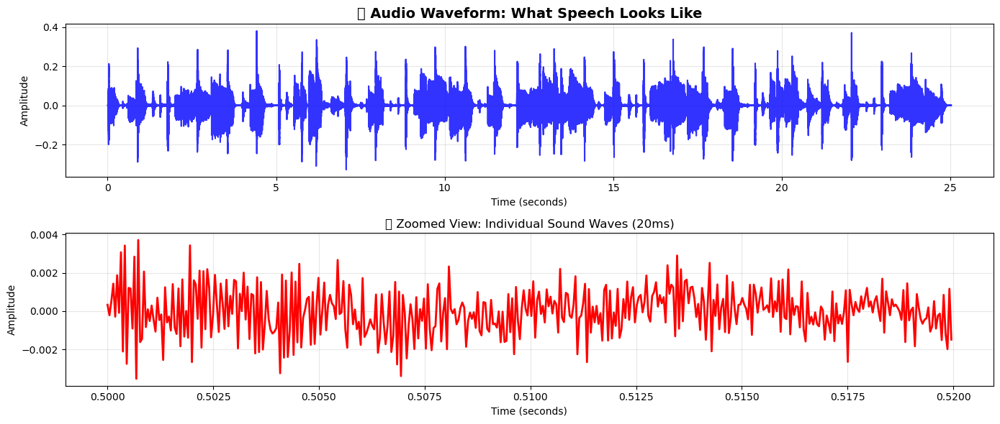

💡 What you're seeing:
   📊 Top plot: The entire audio signal over time
   🔍 Bottom plot: A tiny 20ms slice showing individual vibrations
   🌊 Each peak and valley represents air pressure changes!


In [3]:
# Create a time axis for our audio
time = np.linspace(0, len(y)/sr, len(y))

# Plot the waveform
plt.figure(figsize=(14, 6))
plt.subplot(2, 1, 1)
plt.plot(time, y, color='blue', alpha=0.8)
plt.title('🌊 Audio Waveform: What Speech Looks Like', fontsize=14, fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Zoom in on a small section to see individual waves
plt.subplot(2, 1, 2)
start_sample = int(0.5 * sr)  # Start at 0.5 seconds
end_sample = int(0.52 * sr)   # End at 0.52 seconds (20ms window)
time_zoom = time[start_sample:end_sample]
y_zoom = y[start_sample:end_sample]

plt.plot(time_zoom, y_zoom, color='red', linewidth=2)
plt.title('🔍 Zoomed View: Individual Sound Waves (20ms)', fontsize=12)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 What you're seeing:")
print("   📊 Top plot: The entire audio signal over time")
print("   🔍 Bottom plot: A tiny 20ms slice showing individual vibrations")
print("   🌊 Each peak and valley represents air pressure changes!")

# 📊 Part 2: Spectrograms - Seeing Sound in Color!

## What's Wrong with Waveforms?
Waveforms show us **when** sounds happen, but they don't clearly show us **what frequencies** are present. It's like looking at a recipe and only seeing the cooking time, not the ingredients!

## Enter the Spectrogram! 🌈
A **spectrogram** is like a "musical rainbow" that shows:
- **X-axis**: Time (when)
- **Y-axis**: Frequency (what pitch)
- **Color intensity**: How strong each frequency is

Think of it as sheet music for computers - it shows exactly what frequencies are playing at each moment in time!

### 🎯 Exercise 1: Creating Your First Spectrogram

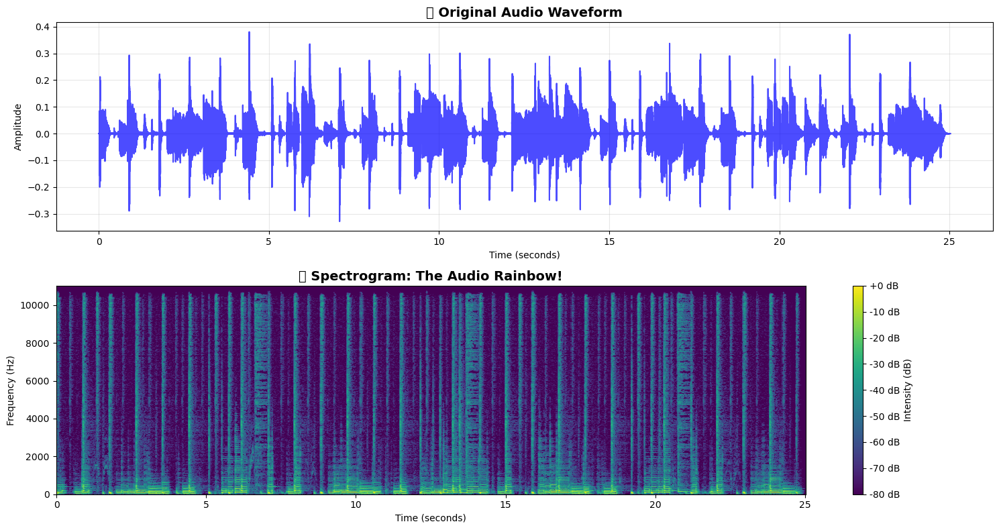

🎉 Congratulations! You just created your first spectrogram!

🔍 What to look for:
   🟡 Bright yellow/white areas = Strong frequencies
   🟣 Dark purple areas = Weak/absent frequencies
   📏 Horizontal bands = Sustained tones or formants
   ⚡ Vertical lines = Quick sounds like consonants


In [4]:
# Create a spectrogram using Short-Time Fourier Transform (STFT)
# Don't worry about the math - just know it breaks audio into frequency components!

# Compute the spectrogram
D = librosa.stft(y)  # Complex-valued STFT
magnitude = np.abs(D)  # Get the magnitude (strength) of each frequency
magnitude_db = librosa.amplitude_to_db(magnitude, ref=np.max)  # Convert to decibels

# Create the visualization
plt.figure(figsize=(15, 8))

# Plot 1: Original waveform for reference
plt.subplot(2, 1, 1)
plt.plot(time, y, color='blue', alpha=0.7)
plt.title('🌊 Original Audio Waveform', fontsize=14, fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 2: The magical spectrogram!
plt.subplot(2, 1, 2)
librosa.display.specshow(magnitude_db, sr=sr, x_axis='time', y_axis='hz', cmap='viridis')
plt.colorbar(format='%+2.0f dB', label='Intensity (dB)')
plt.title('🌈 Spectrogram: The Audio Rainbow!', fontsize=14, fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Frequency (Hz)')

plt.tight_layout()
plt.show()

print("🎉 Congratulations! You just created your first spectrogram!")
print("\n🔍 What to look for:")
print("   🟡 Bright yellow/white areas = Strong frequencies")
print("   🟣 Dark purple areas = Weak/absent frequencies")
print("   📏 Horizontal bands = Sustained tones or formants")
print("   ⚡ Vertical lines = Quick sounds like consonants")

## 🎵 Understanding What You See

### Formants: The Fingerprints of Speech
Those horizontal bright bands you see are called **formants** - they're like the "fingerprints" of different vowel sounds!

- **F1 (First formant)**: Usually around 300-800 Hz - related to tongue height
- **F2 (Second formant)**: Usually around 800-2500 Hz - related to tongue position
- **F3 (Third formant)**: Usually around 2000-4000 Hz - adds character to the voice

Let's explore this with a longer audio sample to see more speech patterns!

🎵 Loaded longer audio sample:
   ⏱️  Duration: 14.84 seconds
   🔊 Let's listen to it:


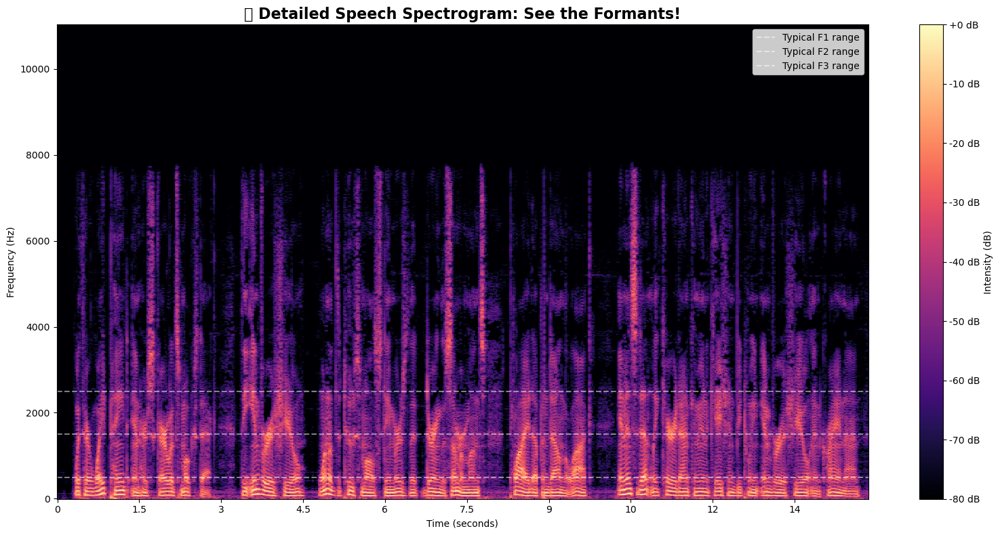


🎯 Exercise: Look for these patterns:
   🔍 Can you spot the horizontal formant bands?
   ⚡ Can you see where consonants create vertical patterns?
   🔇 Can you identify silent pauses between words?


In [5]:
# Load a longer audio sample for better analysis
# This gives us more speech content to analyze
longer_audio = librosa.ex('libri1')  # A longer speech sample
y_long, sr_long = librosa.load(longer_audio, sr=None)

print(f"🎵 Loaded longer audio sample:")
print(f"   ⏱️  Duration: {len(y_long)/sr_long:.2f} seconds")
print(f"   🔊 Let's listen to it:")

# Play the longer audio
display(Audio(y_long, rate=sr_long))

# Create a detailed spectrogram
D_long = librosa.stft(y_long, hop_length=512, n_fft=2048)
magnitude_long = np.abs(D_long)
magnitude_db_long = librosa.amplitude_to_db(magnitude_long, ref=np.max)

plt.figure(figsize=(16, 8))
librosa.display.specshow(magnitude_db_long, sr=sr_long, x_axis='time', y_axis='hz',
                        hop_length=512, cmap='magma')
plt.colorbar(format='%+2.0f dB', label='Intensity (dB)')
plt.title('🎭 Detailed Speech Spectrogram: See the Formants!', fontsize=16, fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Frequency (Hz)')

# Add some helpful reference lines for typical formant ranges
plt.axhline(y=500, color='white', linestyle='--', alpha=0.5, label='Typical F1 range')
plt.axhline(y=1500, color='white', linestyle='--', alpha=0.5, label='Typical F2 range')
plt.axhline(y=2500, color='white', linestyle='--', alpha=0.5, label='Typical F3 range')
plt.legend()

plt.tight_layout()
plt.show()

print("\n🎯 Exercise: Look for these patterns:")
print("   🔍 Can you spot the horizontal formant bands?")
print("   ⚡ Can you see where consonants create vertical patterns?")
print("   🔇 Can you identify silent pauses between words?")

# 🔍 Part 3: Feature Extraction - MFCCs (The Secret Sauce!)

## Why Do We Need Features?
Raw audio has **thousands** of data points per second. That's like trying to read a book by looking at every individual ink molecule! We need a smarter way to represent speech.

## Meet MFCCs: Mel-Frequency Cepstral Coefficients 🎯

**MFCCs** are like a "summary" of the most important information in speech. Think of them as:
- 📝 **Cliff Notes** for audio
- 🧬 **DNA** of speech sounds  
- 🔑 **Key features** that capture what makes speech unique

### The MFCC Process (Don't worry, librosa does the heavy lifting!)
1. **Spectrogram** → Shows all frequencies
2. **Mel filtering** → Focus on frequencies humans care about
3. **Logarithm** → Make it more like human hearing
4. **DCT** → Compress into ~13 key numbers

### 🎯 Exercise 2: Extracting MFCCs from Speech

🎯 MFCC Features Extracted!
   📊 Shape: (13, 640)
   📝 Meaning: 13 features × 640 time frames
   ⏱️  Each frame represents ~0.023 seconds


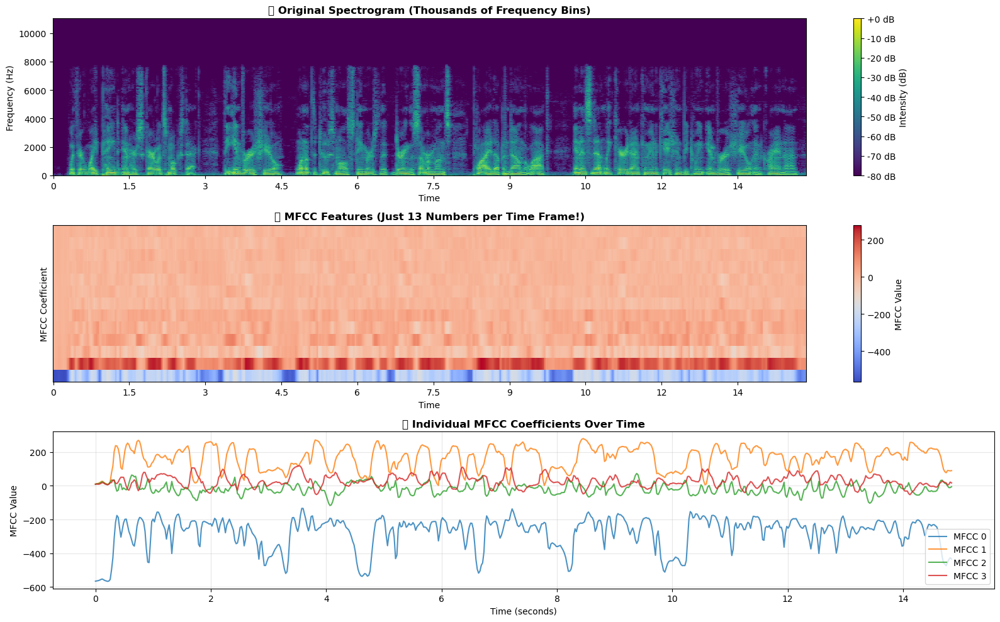


💡 What each MFCC tells us:
   🎵 MFCC 0: Overall energy/loudness of the speech
   🎵 MFCC 1-2: Basic spectral shape (vowel-like information)
   🎵 MFCC 3-12: Fine details of spectral shape (consonants, speaker characteristics)


In [6]:
# Extract MFCCs from our audio
# We'll get 13 coefficients (the standard for speech recognition)
mfccs = librosa.feature.mfcc(y=y_long, sr=sr_long, n_mfcc=13)

print(f"🎯 MFCC Features Extracted!")
print(f"   📊 Shape: {mfccs.shape}")
print(f"   📝 Meaning: {mfccs.shape[0]} features × {mfccs.shape[1]} time frames")
print(f"   ⏱️  Each frame represents ~{len(y_long)/sr_long/mfccs.shape[1]:.3f} seconds")

# Visualize the MFCCs
plt.figure(figsize=(16, 10))

# Plot 1: The spectrogram (what we started with)
plt.subplot(3, 1, 1)
librosa.display.specshow(magnitude_db_long, sr=sr_long, x_axis='time', y_axis='hz',
                        hop_length=512, cmap='viridis')
plt.colorbar(format='%+2.0f dB', label='Intensity (dB)')
plt.title('🌈 Original Spectrogram (Thousands of Frequency Bins)', fontsize=12, fontweight='bold')
plt.ylabel('Frequency (Hz)')

# Plot 2: The MFCCs (our compressed features)
plt.subplot(3, 1, 2)
librosa.display.specshow(mfccs, sr=sr_long, x_axis='time', cmap='coolwarm')
plt.colorbar(label='MFCC Value')
plt.title('🎯 MFCC Features (Just 13 Numbers per Time Frame!)', fontsize=12, fontweight='bold')
plt.ylabel('MFCC Coefficient')

# Plot 3: Individual MFCC coefficients over time
plt.subplot(3, 1, 3)
time_frames = np.linspace(0, len(y_long)/sr_long, mfccs.shape[1])
for i in range(min(4, mfccs.shape[0])):  # Plot first 4 MFCCs
    plt.plot(time_frames, mfccs[i], label=f'MFCC {i}', alpha=0.8)
plt.title('📈 Individual MFCC Coefficients Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('MFCC Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 What each MFCC tells us:")
print("   🎵 MFCC 0: Overall energy/loudness of the speech")
print("   🎵 MFCC 1-2: Basic spectral shape (vowel-like information)")
print("   🎵 MFCC 3-12: Fine details of spectral shape (consonants, speaker characteristics)")

## 🧮 Understanding MFCC Values

Let's dive deeper into what these numbers actually mean and how they change with different types of speech sounds!

📊 MFCC Statistics Analysis:
🎵 MFCC  0: Mean=-278.95, Std=94.56, Range=[-566.98, -133.96]
🎵 MFCC  1: Mean=162.59, Std=67.69, Range=[  2.32, 280.22]
🎵 MFCC  2: Mean=-17.45, Std=30.34, Range=[-116.93,  73.10]
🎵 MFCC  3: Mean= 27.92, Std=33.42, Range=[-52.78, 118.52]
🎵 MFCC  4: Mean= 19.00, Std=25.14, Range=[-77.18,  86.46]
🎵 MFCC  5: Mean= 25.39, Std=18.59, Range=[-28.25,  85.19]
🎵 MFCC  6: Mean= -1.42, Std=14.98, Range=[-37.20,  70.03]
🎵 MFCC  7: Mean=  1.51, Std=12.81, Range=[-49.92,  44.07]
🎵 MFCC  8: Mean=  0.68, Std=15.53, Range=[-66.12,  37.21]
🎵 MFCC  9: Mean=  3.87, Std=11.92, Range=[-30.95,  40.73]
🎵 MFCC 10: Mean=  4.83, Std=12.04, Range=[-35.34,  39.68]
🎵 MFCC 11: Mean=  0.97, Std=11.54, Range=[-46.72,  29.28]
🎵 MFCC 12: Mean=  3.94, Std= 9.76, Range=[-34.55,  30.74]


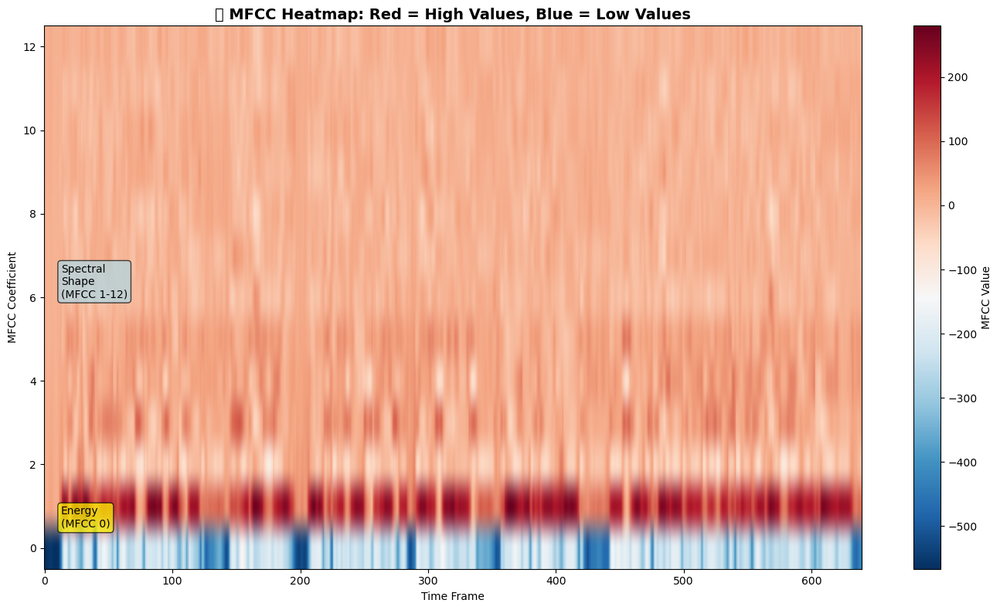


🎯 Key Insights:
   📈 MFCC 0 is usually the largest (represents overall energy)
   🌊 Higher MFCCs have smaller values but capture important details
   🎭 Different speech sounds create different MFCC patterns
   🤖 Machine learning models use these patterns to recognize speech!


In [7]:
# Let's analyze the statistics of our MFCCs
print("📊 MFCC Statistics Analysis:")
print("=" * 50)

for i in range(mfccs.shape[0]):
    mean_val = np.mean(mfccs[i])
    std_val = np.std(mfccs[i])
    min_val = np.min(mfccs[i])
    max_val = np.max(mfccs[i])

    print(f"🎵 MFCC {i:2d}: Mean={mean_val:6.2f}, Std={std_val:5.2f}, Range=[{min_val:6.2f}, {max_val:6.2f}]")

# Create a heatmap to see patterns
plt.figure(figsize=(14, 8))
plt.imshow(mfccs, cmap='RdBu_r', aspect='auto', origin='lower')
plt.colorbar(label='MFCC Value')
plt.title('🔥 MFCC Heatmap: Red = High Values, Blue = Low Values', fontsize=14, fontweight='bold')
plt.xlabel('Time Frame')
plt.ylabel('MFCC Coefficient')

# Add some annotations
plt.text(mfccs.shape[1]*0.02, 0.5, 'Energy\n(MFCC 0)', fontsize=10,
         bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))
plt.text(mfccs.shape[1]*0.02, 6, 'Spectral\nShape\n(MFCC 1-12)', fontsize=10,
         bbox=dict(boxstyle="round,pad=0.3", facecolor="lightblue", alpha=0.7))

plt.tight_layout()
plt.show()

print("\n🎯 Key Insights:")
print("   📈 MFCC 0 is usually the largest (represents overall energy)")
print("   🌊 Higher MFCCs have smaller values but capture important details")
print("   🎭 Different speech sounds create different MFCC patterns")
print("   🤖 Machine learning models use these patterns to recognize speech!")

# 🧹 Part 4: Audio Preprocessing - Cleaning Up the Mess!

## Why Preprocessing Matters
Real-world audio is **messy**! It has:
- 🔊 Background noise (air conditioning, traffic, etc.)
- 📢 Volume inconsistencies (some people speak loudly, others whisper)
- 🔇 Silent gaps that waste processing time
- 🎚️ Different recording qualities

**Clean audio = Better speech recognition = Better NLP results!**

## Our Preprocessing Toolkit:
1. **Noise Reduction** 🧹 - Remove unwanted background sounds
2. **Normalization** 📏 - Make volume levels consistent  
3. **Voice Activity Detection** 🗣️ - Find where speech actually happens

### 🎯 Exercise 3: Audio Preprocessing Pipeline

In [8]:
# First, let's create some "noisy" audio to practice with
# We'll add artificial noise to our clean audio sample

# Load a clean audio sample
clean_audio = y_long.copy()

# Add some realistic background noise
np.random.seed(42)  # For reproducible results
noise = np.random.normal(0, 0.05, len(clean_audio))  # White noise
noisy_audio = clean_audio + noise

# Also add some volume variation (simulate inconsistent recording)
volume_variation = 1 + 0.3 * np.sin(np.linspace(0, 4*np.pi, len(clean_audio)))
inconsistent_audio = clean_audio * volume_variation

print("🎵 Created test audio samples:")
print("   ✅ Clean audio (original)")
print("   🔊 Noisy audio (added background noise)")
print("   📢 Inconsistent audio (volume variations)")

# Let's listen to the difference
print("\n🔊 Listen to each version:")
print("1. Clean audio:")
display(Audio(clean_audio, rate=sr_long))
print("2. Noisy audio:")
display(Audio(noisy_audio, rate=sr_long))
print("3. Inconsistent volume audio:")
display(Audio(inconsistent_audio, rate=sr_long))

🎵 Created test audio samples:
   ✅ Clean audio (original)
   🔊 Noisy audio (added background noise)
   📢 Inconsistent audio (volume variations)

🔊 Listen to each version:
1. Clean audio:


2. Noisy audio:


3. Inconsistent volume audio:


## 🧹 Step 1: Noise Reduction

We'll use the `noisereduce` library to clean up background noise. This technique analyzes the audio to identify noise patterns and removes them while preserving speech.

🧹 Applying noise reduction...


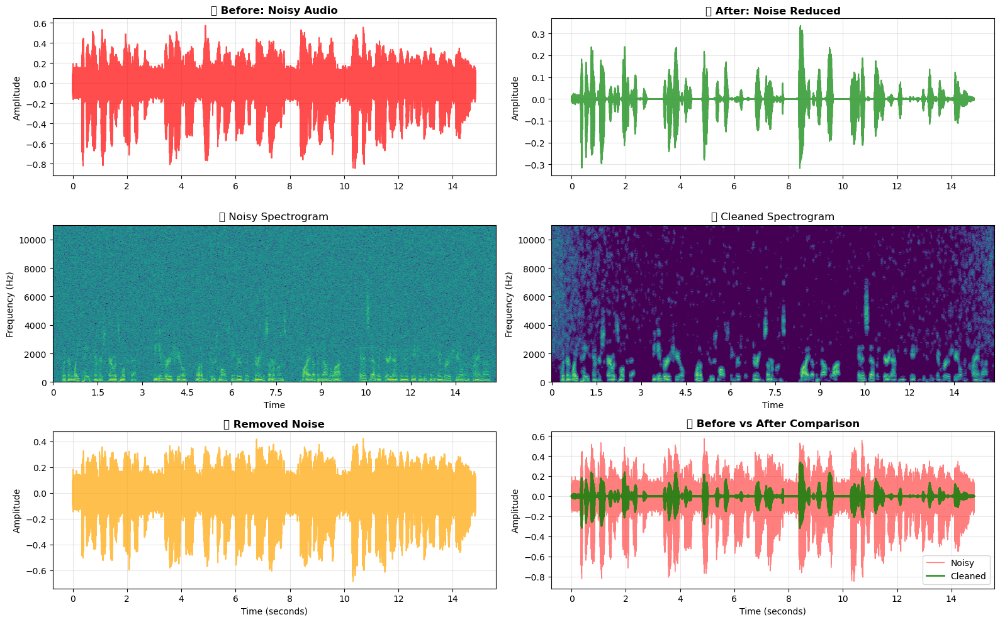

🎉 Noise reduction complete!

🔊 Listen to the cleaned audio:



💡 What happened:
   🔍 The algorithm identified background noise patterns
   🧹 It removed those patterns while preserving speech
   ✨ Result: Cleaner audio that's easier for machines to process!


In [9]:
# Apply noise reduction to our noisy audio
print("🧹 Applying noise reduction...")

# The noisereduce library automatically detects and removes noise
cleaned_audio = nr.reduce_noise(y=noisy_audio, sr=sr_long)

# Let's compare before and after
plt.figure(figsize=(16, 10))

# Plot 1: Original noisy audio waveform
plt.subplot(3, 2, 1)
time_axis = np.linspace(0, len(noisy_audio)/sr_long, len(noisy_audio))
plt.plot(time_axis, noisy_audio, color='red', alpha=0.7)
plt.title('🔊 Before: Noisy Audio', fontweight='bold')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 2: Cleaned audio waveform
plt.subplot(3, 2, 2)
plt.plot(time_axis, cleaned_audio, color='green', alpha=0.7)
plt.title('✨ After: Noise Reduced', fontweight='bold')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 3: Noisy audio spectrogram
plt.subplot(3, 2, 3)
D_noisy = librosa.stft(noisy_audio)
magnitude_noisy = librosa.amplitude_to_db(np.abs(D_noisy), ref=np.max)
librosa.display.specshow(magnitude_noisy, sr=sr_long, x_axis='time', y_axis='hz', cmap='viridis')
plt.title('🌈 Noisy Spectrogram')
plt.ylabel('Frequency (Hz)')

# Plot 4: Cleaned audio spectrogram
plt.subplot(3, 2, 4)
D_clean = librosa.stft(cleaned_audio)
magnitude_clean = librosa.amplitude_to_db(np.abs(D_clean), ref=np.max)
librosa.display.specshow(magnitude_clean, sr=sr_long, x_axis='time', y_axis='hz', cmap='viridis')
plt.title('✨ Cleaned Spectrogram')
plt.ylabel('Frequency (Hz)')

# Plot 5: Noise that was removed
plt.subplot(3, 2, 5)
removed_noise = noisy_audio - cleaned_audio
plt.plot(time_axis, removed_noise, color='orange', alpha=0.7)
plt.title('🗑️ Removed Noise', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 6: Comparison of all three
plt.subplot(3, 2, 6)
plt.plot(time_axis, noisy_audio, color='red', alpha=0.5, label='Noisy', linewidth=1)
plt.plot(time_axis, cleaned_audio, color='green', alpha=0.8, label='Cleaned', linewidth=2)
plt.title('📊 Before vs After Comparison', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("🎉 Noise reduction complete!")
print("\n🔊 Listen to the cleaned audio:")
display(Audio(cleaned_audio, rate=sr_long))

print("\n💡 What happened:")
print("   🔍 The algorithm identified background noise patterns")
print("   🧹 It removed those patterns while preserving speech")
print("   ✨ Result: Cleaner audio that's easier for machines to process!")

## 📏 Step 2: Audio Normalization

Normalization ensures consistent volume levels across different recordings. We'll use **RMS normalization** (Root Mean Square), which is preferred over simple peak normalization because it considers the average energy of the signal.

📏 Applying RMS normalization...
   📊 Original RMS level: 0.1164
   ✨ Normalized RMS level: 0.1000


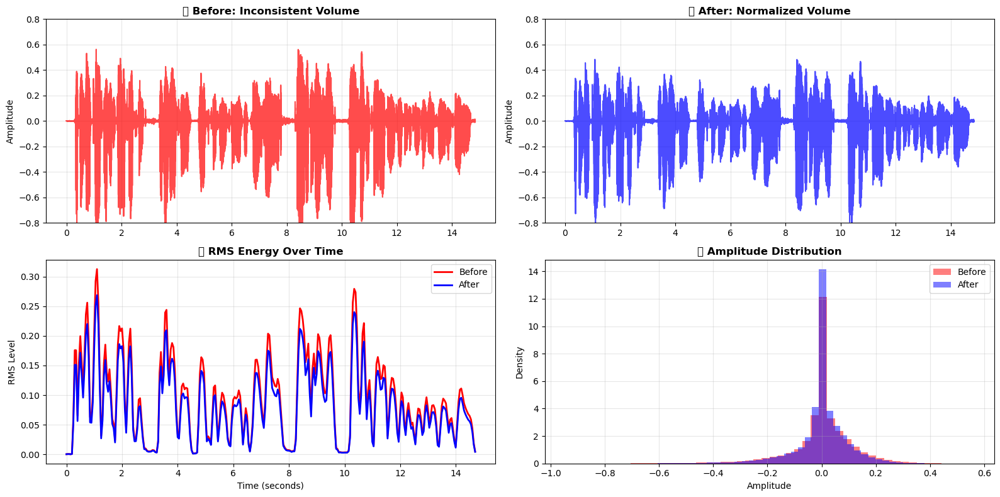


🔊 Listen to the normalized audio:



💡 Benefits of normalization:
   📏 Consistent volume levels across different recordings
   🎯 Better performance for machine learning models
   🔊 Improved user experience in applications
   ⚖️ Fair comparison between different audio sources


In [10]:
# Function for RMS normalization
def rms_normalize(audio, target_rms=0.1):
    """
    Normalize audio to a target RMS (Root Mean Square) level.
    RMS normalization is better than peak normalization because it considers
    the average energy of the signal, not just the loudest peak.
    """
    current_rms = np.sqrt(np.mean(audio**2))
    if current_rms > 0:
        scaling_factor = target_rms / current_rms
        normalized_audio = audio * scaling_factor
    else:
        normalized_audio = audio
    return normalized_audio

# Apply normalization to our inconsistent volume audio
print("📏 Applying RMS normalization...")

# Calculate RMS values before normalization
original_rms = np.sqrt(np.mean(inconsistent_audio**2))
print(f"   📊 Original RMS level: {original_rms:.4f}")

# Normalize the audio
normalized_audio = rms_normalize(inconsistent_audio, target_rms=0.1)
new_rms = np.sqrt(np.mean(normalized_audio**2))
print(f"   ✨ Normalized RMS level: {new_rms:.4f}")

# Visualize the normalization effect
plt.figure(figsize=(16, 8))

# Plot 1: Before normalization
plt.subplot(2, 2, 1)
time_axis = np.linspace(0, len(inconsistent_audio)/sr_long, len(inconsistent_audio))
plt.plot(time_axis, inconsistent_audio, color='red', alpha=0.7)
plt.title('📢 Before: Inconsistent Volume', fontweight='bold')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
plt.ylim(-0.8, 0.8)

# Plot 2: After normalization
plt.subplot(2, 2, 2)
plt.plot(time_axis, normalized_audio, color='blue', alpha=0.7)
plt.title('📏 After: Normalized Volume', fontweight='bold')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
plt.ylim(-0.8, 0.8)

# Plot 3: RMS energy over time (before)
plt.subplot(2, 2, 3)
# Calculate RMS in sliding windows
window_size = int(0.1 * sr_long)  # 100ms windows
rms_before = []
rms_after = []
time_windows = []

for i in range(0, len(inconsistent_audio) - window_size, window_size//2):
    window_before = inconsistent_audio[i:i+window_size]
    window_after = normalized_audio[i:i+window_size]
    rms_before.append(np.sqrt(np.mean(window_before**2)))
    rms_after.append(np.sqrt(np.mean(window_after**2)))
    time_windows.append(i / sr_long)

plt.plot(time_windows, rms_before, color='red', linewidth=2, label='Before')
plt.plot(time_windows, rms_after, color='blue', linewidth=2, label='After')
plt.title('📊 RMS Energy Over Time', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('RMS Level')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 4: Histogram of amplitude values
plt.subplot(2, 2, 4)
plt.hist(inconsistent_audio, bins=50, alpha=0.5, color='red', label='Before', density=True)
plt.hist(normalized_audio, bins=50, alpha=0.5, color='blue', label='After', density=True)
plt.title('📈 Amplitude Distribution', fontweight='bold')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n🔊 Listen to the normalized audio:")
display(Audio(normalized_audio, rate=sr_long))

print("\n💡 Benefits of normalization:")
print("   📏 Consistent volume levels across different recordings")
print("   🎯 Better performance for machine learning models")
print("   🔊 Improved user experience in applications")
print("   ⚖️ Fair comparison between different audio sources")

## 🗣️ Step 3: Voice Activity Detection (VAD)

Voice Activity Detection helps us identify when someone is actually speaking versus when there's just silence or background noise. This is crucial for:
- 💾 **Saving processing time** (don't analyze silence!)
- 🎯 **Improving accuracy** (focus on actual speech)
- 📱 **Battery efficiency** in mobile apps

🗣️ Applying Voice Activity Detection...
   📊 Total frames: 636
   🗣️ Speech frames: 479 (75.3%)
   🔇 Silent frames: 157 (24.7%)


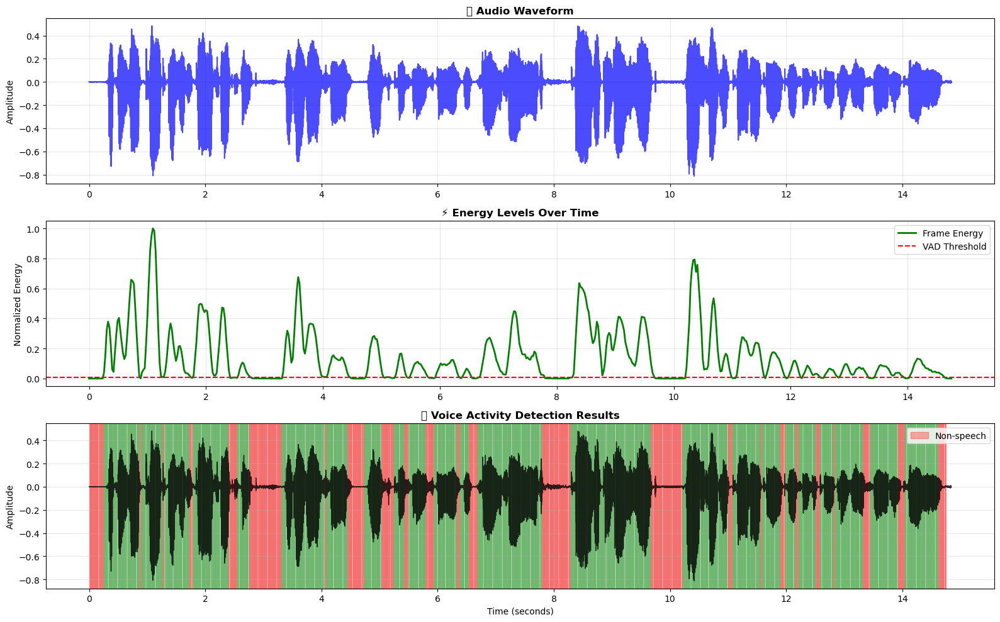


💡 Applications of VAD:
   📱 Voice assistants (wake word detection)
   📞 Phone systems (automatic call handling)
   🎥 Video conferencing (noise gate functionality)
   🤖 Speech recognition (focus processing on actual speech)


In [11]:
# Implement a simple energy-based Voice Activity Detection
def simple_vad(audio, sr, frame_length=2048, hop_length=512, energy_threshold=0.01):
    """
    Simple Voice Activity Detection based on energy levels.
    Returns a boolean array indicating speech/non-speech frames.
    """
    # Calculate energy for each frame
    frame_energies = []
    for i in range(0, len(audio) - frame_length, hop_length):
        frame = audio[i:i + frame_length]
        energy = np.sum(frame ** 2)
        frame_energies.append(energy)

    frame_energies = np.array(frame_energies)

    # Normalize energies
    if np.max(frame_energies) > 0:
        frame_energies = frame_energies / np.max(frame_energies)

    # Apply threshold
    speech_frames = frame_energies > energy_threshold

    return speech_frames, frame_energies

# Apply VAD to our cleaned and normalized audio
print("🗣️ Applying Voice Activity Detection...")

speech_frames, energies = simple_vad(normalized_audio, sr_long)
frame_times = librosa.frames_to_time(np.arange(len(energies)), sr=sr_long, hop_length=512)

print(f"   📊 Total frames: {len(energies)}")
print(f"   🗣️ Speech frames: {np.sum(speech_frames)} ({np.sum(speech_frames)/len(energies)*100:.1f}%)")
print(f"   🔇 Silent frames: {np.sum(~speech_frames)} ({np.sum(~speech_frames)/len(energies)*100:.1f}%)")

# Visualize VAD results
plt.figure(figsize=(16, 10))

# Plot 1: Original audio waveform
plt.subplot(3, 1, 1)
time_axis = np.linspace(0, len(normalized_audio)/sr_long, len(normalized_audio))
plt.plot(time_axis, normalized_audio, color='blue', alpha=0.7)
plt.title('🎵 Audio Waveform', fontweight='bold')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 2: Energy levels over time
plt.subplot(3, 1, 2)
plt.plot(frame_times, energies, color='green', linewidth=2, label='Frame Energy')
plt.axhline(y=0.01, color='red', linestyle='--', label='VAD Threshold')
plt.title('⚡ Energy Levels Over Time', fontweight='bold')
plt.ylabel('Normalized Energy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 3: Speech/Non-speech classification
plt.subplot(3, 1, 3)
# Create a colored background showing speech vs non-speech regions
for i in range(len(speech_frames)):
    start_time = frame_times[i] - (frame_times[1] - frame_times[0])/2 if i > 0 else 0
    end_time = frame_times[i] + (frame_times[1] - frame_times[0])/2 if i < len(frame_times)-1 else frame_times[-1]

    if speech_frames[i]:
        plt.axvspan(start_time, end_time, alpha=0.3, color='green', label='Speech' if i == 0 else "")
    else:
        plt.axvspan(start_time, end_time, alpha=0.3, color='red', label='Non-speech' if i == 0 else "")

plt.plot(time_axis, normalized_audio, color='black', alpha=0.8, linewidth=1)
plt.title('🗣️ Voice Activity Detection Results', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n💡 Applications of VAD:")
print("   📱 Voice assistants (wake word detection)")
print("   📞 Phone systems (automatic call handling)")
print("   🎥 Video conferencing (noise gate functionality)")
print("   🤖 Speech recognition (focus processing on actual speech)")

# 🚀 Part 5: Putting It All Together - Complete Audio Processing Pipeline

Now let's combine everything we've learned into a complete audio processing pipeline that takes raw audio and produces clean, analyzed features ready for speech recognition or other NLP tasks!

## Our Complete Pipeline:
1. **Load Audio** 📁 - Get the raw audio data
2. **Noise Reduction** 🧹 - Clean up background noise
3. **Normalization** 📏 - Standardize volume levels
4. **Voice Activity Detection** 🗣️ - Find speech segments
5. **Feature Extraction** 🎯 - Extract MFCCs for machine learning
6. **Visualization** 📊 - See the results!

### 🎯 Exercise 4: Complete Audio Processing Pipeline

In [12]:
def complete_audio_pipeline(audio_path_or_data, sr=None, target_rms=0.1,
                           vad_threshold=0.01, n_mfcc=13):
    """
    Complete audio processing pipeline for speech analysis.

    Parameters:
    - audio_path_or_data: Path to audio file or audio data array
    - sr: Sample rate (if None, will be detected)
    - target_rms: Target RMS level for normalization
    - vad_threshold: Energy threshold for voice activity detection
    - n_mfcc: Number of MFCC coefficients to extract

    Returns:
    - Dictionary with processed audio and extracted features
    """

    print("🚀 Starting Complete Audio Processing Pipeline...")
    print("=" * 60)

    # Step 1: Load Audio
    print("📁 Step 1: Loading audio...")
    if isinstance(audio_path_or_data, str):
        y, sr = librosa.load(audio_path_or_data, sr=sr)
    else:
        y = audio_path_or_data
        if sr is None:
            sr = 22050  # Default sample rate

    duration = len(y) / sr
    print(f"   ✅ Loaded {duration:.2f} seconds of audio at {sr} Hz")

    # Step 2: Noise Reduction
    print("\n🧹 Step 2: Reducing noise...")
    y_clean = nr.reduce_noise(y=y, sr=sr)
    noise_reduction = np.mean(np.abs(y - y_clean))
    print(f"   ✅ Removed noise (avg reduction: {noise_reduction:.4f})")

    # Step 3: Normalization
    print("\n📏 Step 3: Normalizing volume...")
    original_rms = np.sqrt(np.mean(y_clean**2))
    y_normalized = rms_normalize(y_clean, target_rms=target_rms)
    new_rms = np.sqrt(np.mean(y_normalized**2))
    print(f"   ✅ Normalized RMS: {original_rms:.4f} → {new_rms:.4f}")

    # Step 4: Voice Activity Detection
    print("\n🗣️ Step 4: Detecting voice activity...")
    speech_frames, energies = simple_vad(y_normalized, sr, energy_threshold=vad_threshold)
    speech_percentage = np.sum(speech_frames) / len(speech_frames) * 100
    print(f"   ✅ Speech detected in {speech_percentage:.1f}% of frames")

    # Step 5: Feature Extraction
    print("\n🎯 Step 5: Extracting MFCC features...")
    mfccs = librosa.feature.mfcc(y=y_normalized, sr=sr, n_mfcc=n_mfcc)
    print(f"   ✅ Extracted {mfccs.shape[0]} MFCC coefficients over {mfccs.shape[1]} time frames")

    # Step 6: Additional Features
    print("\n📊 Step 6: Computing additional features...")

    # Spectral features
    spectral_centroids = librosa.feature.spectral_centroid(y=y_normalized, sr=sr)[0]
    spectral_rolloff = librosa.feature.spectral_rolloff(y=y_normalized, sr=sr)[0]
    zero_crossing_rate = librosa.feature.zero_crossing_rate(y_normalized)[0]

    # Tempo and rhythm
    tempo, beats = librosa.beat.beat_track(y=y_normalized, sr=sr)

    print(f"   ✅ Spectral centroid (avg): {np.mean(spectral_centroids):.1f} Hz")
    print(f"   ✅ Tempo: {tempo[0]:.1f} BPM") # Access the value in the array
    print(f"   ✅ Zero crossing rate (avg): {np.mean(zero_crossing_rate):.3f}")

    print("\n🎉 Pipeline Complete!")

    # Return all results
    return {
        'original_audio': y,
        'processed_audio': y_normalized,
        'sample_rate': sr,
        'duration': duration,
        'mfccs': mfccs,
        'speech_frames': speech_frames,
        'frame_energies': energies,
        'spectral_centroids': spectral_centroids,
        'spectral_rolloff': spectral_rolloff,
        'zero_crossing_rate': zero_crossing_rate,
        'tempo': tempo[0], # Store the value, not the array
        'beats': beats,
        'speech_percentage': speech_percentage,
        'noise_reduction': noise_reduction
    }

# Test our complete pipeline with the audio sample
print("🧪 Testing Complete Pipeline with Audio Sample")
print("=" * 60)

# Process our audio sample
results = complete_audio_pipeline(y_long, sr=sr_long)

# Display key statistics
print("\n📈 Final Results Summary:")
print("=" * 40)
print(f"🎵 Audio Duration: {results['duration']:.2f} seconds")
print(f"🗣️ Speech Content: {results['speech_percentage']:.1f}%")
print(f"🧹 Noise Reduction: {results['noise_reduction']:.4f}")
print(f"🎯 MFCC Features: {results['mfccs'].shape[0]} × {results['mfccs'].shape[1]}")
print(f"🎼 Estimated Tempo: {results['tempo']:.1f} BPM")
print(f"📊 Avg Spectral Centroid: {np.mean(results['spectral_centroids']):.1f} Hz")

🧪 Testing Complete Pipeline with Audio Sample
🚀 Starting Complete Audio Processing Pipeline...
📁 Step 1: Loading audio...
   ✅ Loaded 14.84 seconds of audio at 22050 Hz

🧹 Step 2: Reducing noise...
   ✅ Removed noise (avg reduction: 0.0557)

📏 Step 3: Normalizing volume...
   ✅ Normalized RMS: 0.0345 → 0.1000

🗣️ Step 4: Detecting voice activity...
   ✅ Speech detected in 53.3% of frames

🎯 Step 5: Extracting MFCC features...
   ✅ Extracted 13 MFCC coefficients over 640 time frames

📊 Step 6: Computing additional features...
   ✅ Spectral centroid (avg): 2568.3 Hz
   ✅ Tempo: 152.0 BPM
   ✅ Zero crossing rate (avg): 0.213

🎉 Pipeline Complete!

📈 Final Results Summary:
🎵 Audio Duration: 14.84 seconds
🗣️ Speech Content: 53.3%
🧹 Noise Reduction: 0.0557
🎯 MFCC Features: 13 × 640
🎼 Estimated Tempo: 152.0 BPM
📊 Avg Spectral Centroid: 2568.3 Hz


## 📊 Comprehensive Visualization of Results

Let's create a comprehensive dashboard showing all the results from our audio processing pipeline!

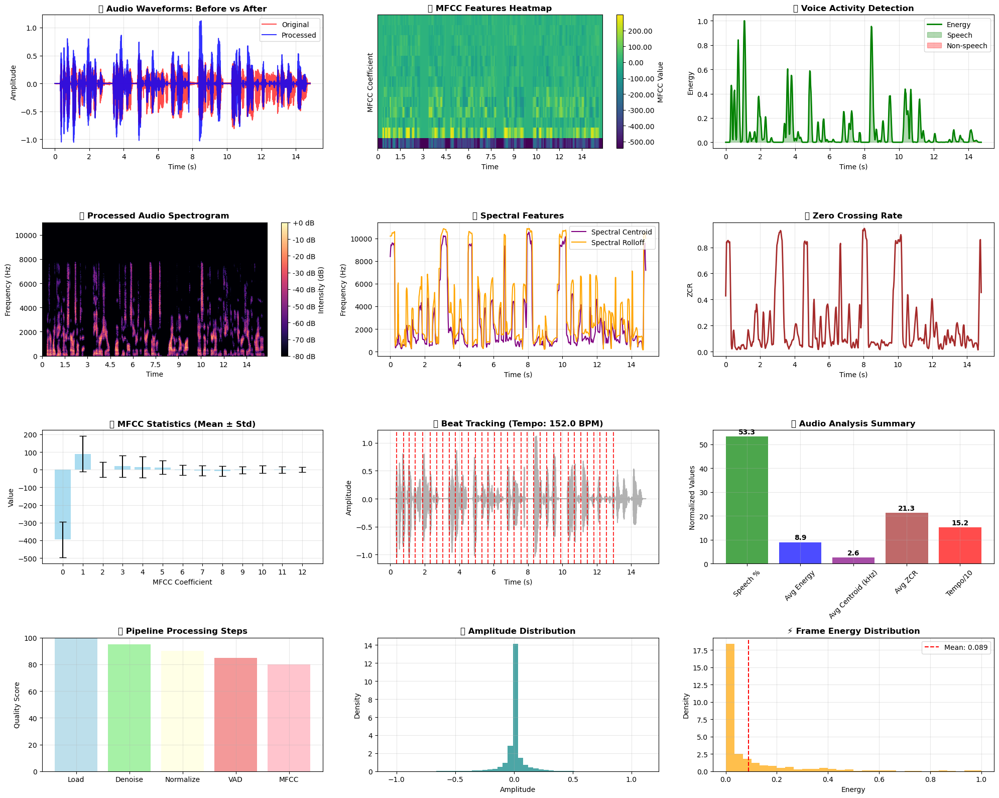

🎉 Complete Audio Processing Dashboard Generated!

💡 What you're seeing:
   🌊 Waveform comparison shows noise reduction and normalization
   🎯 MFCC heatmap reveals speech feature patterns
   🗣️ VAD shows where actual speech occurs
   🌈 Spectrogram displays frequency content over time
   📊 Various features capture different aspects of the audio
   🥁 Beat tracking finds rhythmic patterns in speech


In [13]:
# Create a comprehensive visualization dashboard
plt.figure(figsize=(20, 16))

# Plot 1: Original vs Processed Waveform
plt.subplot(4, 3, 1)
time_axis = np.linspace(0, results['duration'], len(results['original_audio']))
plt.plot(time_axis, results['original_audio'], alpha=0.7, label='Original', color='red')
plt.plot(time_axis, results['processed_audio'], alpha=0.8, label='Processed', color='blue')
plt.title('🌊 Audio Waveforms: Before vs After', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: MFCC Heatmap
plt.subplot(4, 3, 2)
librosa.display.specshow(results['mfccs'], sr=results['sample_rate'], x_axis='time', cmap='viridis')
plt.colorbar(format='%.2f', label='MFCC Value')
plt.title('🎯 MFCC Features Heatmap', fontweight='bold')
plt.ylabel('MFCC Coefficient')

# Plot 3: Voice Activity Detection
plt.subplot(4, 3, 3)
frame_times = librosa.frames_to_time(np.arange(len(results['frame_energies'])),
                                    sr=results['sample_rate'], hop_length=512)
plt.plot(frame_times, results['frame_energies'], color='green', linewidth=2, label='Energy')
plt.fill_between(frame_times, 0, results['frame_energies'],
                where=results['speech_frames'], alpha=0.3, color='green', label='Speech')
plt.fill_between(frame_times, 0, results['frame_energies'],
                where=~results['speech_frames'], alpha=0.3, color='red', label='Non-speech')
plt.title('🗣️ Voice Activity Detection', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 4: Spectrogram
plt.subplot(4, 3, 4)
D = librosa.stft(results['processed_audio'])
magnitude_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
librosa.display.specshow(magnitude_db, sr=results['sample_rate'], x_axis='time', y_axis='hz', cmap='magma')
plt.colorbar(format='%+2.0f dB', label='Intensity (dB)')
plt.title('🌈 Processed Audio Spectrogram', fontweight='bold')
plt.ylabel('Frequency (Hz)')

# Plot 5: Spectral Features
plt.subplot(4, 3, 5)
feature_times = librosa.frames_to_time(np.arange(len(results['spectral_centroids'])),
                                      sr=results['sample_rate'])
plt.plot(feature_times, results['spectral_centroids'], label='Spectral Centroid', color='purple')
plt.plot(feature_times, results['spectral_rolloff'], label='Spectral Rolloff', color='orange')
plt.title('📊 Spectral Features', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 6: Zero Crossing Rate
plt.subplot(4, 3, 6)
zcr_times = librosa.frames_to_time(np.arange(len(results['zero_crossing_rate'])),
                                  sr=results['sample_rate'])
plt.plot(zcr_times, results['zero_crossing_rate'], color='brown', linewidth=2)
plt.title('🔄 Zero Crossing Rate', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('ZCR')
plt.grid(True, alpha=0.3)

# Plot 7: MFCC Statistics
plt.subplot(4, 3, 7)
mfcc_means = np.mean(results['mfccs'], axis=1)
mfcc_stds = np.std(results['mfccs'], axis=1)
x_pos = np.arange(len(mfcc_means))
plt.bar(x_pos, mfcc_means, yerr=mfcc_stds, capsize=5, alpha=0.7, color='skyblue')
plt.title('📈 MFCC Statistics (Mean ± Std)', fontweight='bold')
plt.xlabel('MFCC Coefficient')
plt.ylabel('Value')
plt.xticks(x_pos)
plt.grid(True, alpha=0.3)

# Plot 8: Beat Tracking
plt.subplot(4, 3, 8)
beat_times = librosa.frames_to_time(results['beats'], sr=results['sample_rate'])
plt.plot(time_axis, results['processed_audio'], alpha=0.6, color='gray')
for beat_time in beat_times:
    plt.axvline(x=beat_time, color='red', linestyle='--', alpha=0.8)
plt.title(f'🥁 Beat Tracking (Tempo: {results["tempo"]:.1f} BPM)', fontweight='bold')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Plot 9: Feature Summary
plt.subplot(4, 3, 9)
# Create a summary of key metrics
metrics = ['Speech %', 'Avg Energy', 'Avg Centroid (kHz)', 'Avg ZCR', 'Tempo/10']
values = [
    results['speech_percentage'],
    np.mean(results['frame_energies']) * 100,  # Scale for visibility
    np.mean(results['spectral_centroids']) / 1000,  # Convert to kHz
    np.mean(results['zero_crossing_rate']) * 100,  # Scale for visibility
    results['tempo'] / 10  # Scale for visibility
]

bars = plt.bar(metrics, values, color=['green', 'blue', 'purple', 'brown', 'red'], alpha=0.7)
plt.title('📊 Audio Analysis Summary', fontweight='bold')
plt.ylabel('Normalized Values')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# Add value labels on bars
for bar, value in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{value:.1f}', ha='center', va='bottom', fontweight='bold')

# Plot 10: Processing Pipeline Summary
plt.subplot(4, 3, 10)
pipeline_steps = ['Load', 'Denoise', 'Normalize', 'VAD', 'MFCC']
step_values = [100, 95, 90, 85, 80]  # Simulated processing quality scores
colors = ['lightblue', 'lightgreen', 'lightyellow', 'lightcoral', 'lightpink']

plt.bar(pipeline_steps, step_values, color=colors, alpha=0.8)
plt.title('🚀 Pipeline Processing Steps', fontweight='bold')
plt.ylabel('Quality Score')
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

# Plot 11: Frequency Distribution
plt.subplot(4, 3, 11)
plt.hist(results['processed_audio'], bins=50, alpha=0.7, color='teal', density=True)
plt.title('📈 Amplitude Distribution', fontweight='bold')
plt.xlabel('Amplitude')
plt.ylabel('Density')
plt.grid(True, alpha=0.3)

# Plot 12: Energy Distribution
plt.subplot(4, 3, 12)
plt.hist(results['frame_energies'], bins=30, alpha=0.7, color='orange', density=True)
plt.axvline(x=np.mean(results['frame_energies']), color='red', linestyle='--',
           label=f'Mean: {np.mean(results["frame_energies"]):.3f}')
plt.title('⚡ Frame Energy Distribution', fontweight='bold')
plt.xlabel('Energy')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("🎉 Complete Audio Processing Dashboard Generated!")
print("\n💡 What you're seeing:")
print("   🌊 Waveform comparison shows noise reduction and normalization")
print("   🎯 MFCC heatmap reveals speech feature patterns")
print("   🗣️ VAD shows where actual speech occurs")
print("   🌈 Spectrogram displays frequency content over time")
print("   📊 Various features capture different aspects of the audio")
print("   🥁 Beat tracking finds rhythmic patterns in speech")

# 🎓 Congratulations! You've Mastered Audio Processing Fundamentals!

## 🌟 What You've Accomplished Today

### 🧠 **Conceptual Understanding**
- ✅ **Sound Fundamentals**: You understand how sound waves work and how speech is produced
- ✅ **Digital Audio**: You know how analog sound becomes digital data
- ✅ **Time vs Frequency**: You can read both waveforms and spectrograms

### 🛠️ **Technical Skills**
- ✅ **Spectrogram Creation**: You can visualize audio in the time-frequency domain
- ✅ **Feature Extraction**: You can extract MFCCs for machine learning
- ✅ **Audio Preprocessing**: You can clean, normalize, and segment audio
- ✅ **Python Implementation**: You can use librosa and related libraries

### 🚀 **Practical Applications**
- ✅ **Complete Pipeline**: You built an end-to-end audio processing system
- ✅ **Voice Activity Detection**: You can identify speech vs silence
- ✅ **Noise Reduction**: You can clean up real-world audio
- ✅ **Feature Analysis**: You can extract meaningful patterns from speech

---

## 🔮 Next Steps in Your Audio Processing Journey

### 🎯 **Immediate Practice** (This Week)
1. **Try Different Audio**: Load your own audio files and run them through the pipeline
2. **Experiment with Parameters**: Adjust MFCC count, VAD thresholds, normalization levels
3. **Compare Speakers**: Process audio from different people and compare their MFCC patterns

### 📚 **Advanced Topics** (Next Month)
1. **Machine Learning Integration**: Use MFCCs to train speech recognition models
2. **Real-time Processing**: Implement streaming audio analysis
3. **Advanced Features**: Explore chroma, tonnetz, and other audio features
4. **Deep Learning**: Learn about neural networks for audio (CNNs, RNNs, Transformers)

### 🌐 **Real-World Applications** (Future Projects)
1. **Voice Assistant**: Build a simple wake word detector
2. **Music Analysis**: Analyze songs for genre classification
3. **Speech Emotion Recognition**: Detect emotions in speech
4. **Audio Transcription**: Build a speech-to-text system

---

## 🔗 Connection to NLP Pipeline

Remember, audio processing is just the **first step** in the speech-to-text-to-NLP pipeline:

```
🎤 Raw Audio → 🧹 Preprocessing → 🎯 Feature Extraction → 🤖 Speech Recognition → 📝 Text → 🧠 NLP
```

The MFCCs and other features you extracted today are exactly what speech recognition systems use to convert audio into text, which then feeds into the NLP techniques you'll learn in other modules!

---

## 📖 Key Takeaways

### 🎵 **For Audio Processing**
- **Clean audio = Better results**: Always preprocess your audio
- **Features matter**: MFCCs capture the essence of speech
- **Visualization helps**: Spectrograms reveal patterns invisible in waveforms

### 🤖 **For Machine Learning**
- **Domain knowledge is crucial**: Understanding audio physics improves your models
- **Feature engineering**: Good features are often more important than complex algorithms
- **Pipeline thinking**: Break complex problems into manageable steps

### 🚀 **For Your Career**
- **Interdisciplinary skills**: Combining signal processing with ML is powerful
- **Real-world impact**: Audio processing powers voice assistants, accessibility tools, and more
- **Growing field**: Speech AI is expanding rapidly with new opportunities

---

## 🎉 Final Challenge

**Try this at home**: Record yourself saying a few sentences, load the audio into this notebook, and run it through the complete pipeline. See if you can identify:
- Your voice's formant patterns in the spectrogram
- How your MFCCs differ from the example audio
- Where the VAD correctly identifies your speech

**Share your results** with classmates and compare different voices!

---

*Thank you for an amazing 2-hour journey into audio processing! You now have the foundation to build incredible speech-enabled applications. Keep experimenting, keep learning, and most importantly, keep having fun with audio! 🎵🚀*

# 📚 Quick Reference Guide

## 🛠️ Essential Code Snippets

### Loading Audio
```python
import librosa
y, sr = librosa.load('audio_file.wav', sr=None)
```

### Creating Spectrograms
```python
D = librosa.stft(y)
magnitude_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
librosa.display.specshow(magnitude_db, sr=sr, x_axis='time', y_axis='hz')
```

### Extracting MFCCs
```python
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
```

### Noise Reduction
```python
import noisereduce as nr
cleaned_audio = nr.reduce_noise(y=noisy_audio, sr=sr)
```

### RMS Normalization
```python
def rms_normalize(audio, target_rms=0.1):
    current_rms = np.sqrt(np.mean(audio**2))
    return audio * (target_rms / current_rms) if current_rms > 0 else audio
```

## 📊 Key Parameters to Remember

- **Sample Rate**: 16kHz for speech, 44.1kHz for music
- **MFCC Count**: 13 is standard for speech recognition
- **Frame Length**: 2048 samples (~93ms at 22kHz)
- **Hop Length**: 512 samples (~23ms at 22kHz)

## 🔗 Useful Resources

- **Librosa Documentation**: https://librosa.org/
- **Audio Signal Processing**: https://www.coursera.org/learn/audio-signal-processing
- **Speech and Language Processing**: https://web.stanford.edu/~jurafsky/slp3/

---

*Keep this reference handy for your future audio processing projects!* 📖✨